In [1]:
import jax_sn as jsn
%load_ext autoreload
%autoreload 2
import jax_sbgeom

import jax.numpy as jnp
import numpy as onp
from typing import Tuple
import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)
from jax_sn.operators.transport_operator import TransportOperatorBatched, TransportOperatorMultipleAnglesVmap, TransportOperatorVmap, TransportOperatorBatchedPallas, TransportOperatorMultipleAngles
from jax_sn.domain.cross_sections import CrossSectionIndexed
import equinox as eqx
from typing import List
from jax_sn.tools.mesh_tools import _pad_last_dimension
import matplotlib.pyplot as plt
from dataclasses import dataclass
onp.set_printoptions(linewidth = 200)
from finite_elements.test_moment_scatter_operator import _setup_all_sb

In [2]:
from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex
from jax_sn.solution_domain import SolutionDomain
from jax_sn.domain import CrossSectionData, Domain
from jax_sn.source import Source
from jax_sn.tools.memory_analysis import _filter_jit_f_to_memory
import lineax as lx

In [3]:
from finite_elements.test_breeding_blanket import bb_data_dict, base_region_sizes, base_resolutions,  _get_bb_args, _setup_bb_args, _get_bb_args


def setup_mgop(dim, degree):
    MGOP, source_eg0, solution_domain = _setup_bb_args(dim, degree, base_region_sizes(), base_resolutions(), 5.0, 10, 3)
    transport_operator                = TransportOperatorMultipleAnglesVmap(TransportOperatorBatchedPallas(MGOP.transport_operator.solution_domain_data, MGOP.transport_operator.topological_sorted_angle, 0, 100))
    MGOP                              = eqx.tree_at(lambda t : t.transport_operator, MGOP, transport_operator)
    return MGOP, source_eg0, solution_domain

def setup_mgop_mod_theta(dim, degree, xs_data_indices, dx):
    MGOP, source_eg0, solution_domain = setup_mgop(dim, degree)    

    total_xs = MGOP.transport_operator.solution_domain_data.domain.cross_sections_indexed.cross_section_data.total
    scattering_xs = MGOP.transport_operator.solution_domain_data.domain.cross_sections_indexed.cross_section_data.scattering    
    if xs_data_indices[0] == 'total':
        total_xs = total_xs.at[xs_data_indices[1]].add(dx)
        
    elif xs_data_indices[0] == 'scattering':
        scattering_xs = scattering_xs.at[xs_data_indices[1]].add(dx)
    else:
        raise ValueError("Invalid xs_data_indices")    
    
    sgop = MGOP.to_single_group_operator(0)

    xs_data_new = CrossSectionData(total_xs, scattering_xs)
    sgop_new = eqx.tree_at(lambda sgop : [sgop.transport_operator.solution_domain_data.domain.cross_sections_indexed.cross_section_data, sgop.inscatter_operator.cross_sections_indexed.cross_section_data], sgop,[xs_data_new,xs_data_new])
    return sgop_new, source_eg0, solution_domain


MGOP, source_eg0, solution_domain = setup_mgop(2,2)

In [4]:
MGOP.n_elements

500

In [5]:
from jax_sn.operators.moment_operator import MomentOperator
from jax_sn.operators.transport_operator import TransportOperatorMultipleAngles
from jax_sn.operators.mass_operator import MassOperator
from jax_sn.operators.scatter_operator.gather_scatter_operator_imp import GatherScatterOperator
from jax_sn.operators.moment_operator import DiscreteOperator
from jax_sn.operators.multi_group_operator import MultiGroupOperator


In [32]:
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver

bicgstab = lx.BiCGStab(1e-8, 1e-10, max_steps = 59)

rhs_0 = MGOP.moment_operator.mv(MGOP.transport_operator.to_energy_group(0).inv(MGOP.mass_operator.mv(source_eg0)))
rhs_total = jnp.stack([rhs_0]+ [jnp.zeros_like(rhs_0) for _ in range(MGOP.n_energy_groups -1)], axis=0)

solver = MultiGroupLowerTriangularBlockSolver(bicgstab)
result = lx.linear_solve(MGOP, rhs_total, solver)

In [42]:
from jax_sn.tools.memory_analysis import MultiGroupOperatorSigmaAllParametrised

theta_base = MultiGroupOperatorSigmaAllParametrised.theta_base(MGOP)

In [ ]:

@eqx.filter_jit
def solve_upper_triangular_transpose(mgop : MultiGroupOperator, solver, rhs : jnp.ndarray) -> jnp.ndarray:
    r'''
    Solve the linear system using a given solver, assuming the multi-group operator is lower triangular.
    This is useful for e.g. downscattering only problems. 

    Mathematical Description
    ---------------------------
    In a downscattering only problem, the multi-group operator has the structure:

    .. math::
        \mathbf{A} = \begin{bmatrix} \mathbf{A}_0 & 0 & 0 & \dots &0 \\ B_{10} & \mathbf{A}_1 &0 & \dots & 0 \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ B_{G0} & B_{G1} & B_{G2} & \dots & \mathbf{A}_G \end{bmatrix}

    This can be solved by direct block forward substitution, solving each energy group sequentially using the single-group operator for that group and the already computed higher energy group solutions to form the scattering source.

    The right-hand side is then, for a specific energy group g:

    .. math::
        \text{rhs}_g + \sum_{g' < g} \mathbf{B}_{gg'}[\psi_{g'}] = \text{rhs}_g + \mathbf{M}\mathbf{T}_g^{-1}\mathbf{H}\mathbf{D} \imes \sum_{g' < g} \mathbf{S}_{gg'}[\psi_{g'}] \equiv \text{rhs}_g + \mathbf{M}\mathbf{T}_g^{-1}\mathbf{H}\mathbf{D} \mathbf{U}_g[\\psi]

    where we use that for higher energy groups :math:`g' < g`, the scattering operator is zero (since we use the gather scattering of a general :class:`MultiGroupOperator` here, the others are still used, but they are just zero).

    The single group system is then solved with the :class:`SingleGroupOperator` for energy group g.

    Parameters
    ----------
    mgop : MultiGroupOperator
        The multi group operator.
    solver : lx.LinearSolver
        The linear solver to use.
    rhs : jnp.ndarray
        The right-hand side.
    Returns
    -------
    jnp.ndarray
        The solution.   
    '''
    n_groups = mgop.n_energy_groups        

    def body_fun(i, state):                
        solution, n_steps = state
        sgop = mgop.to_single_group_operator(i)        

        rhs_i = rhs[i] + mgop.moment_operator.mv(sgop.transport_operator.inv(mgop.mass_operator.mv(mgop.discrete_operator.mv(mgop.gather_scatter_operator.gather_forward(solution, i)))))
        lxsolve = lx.linear_solve(sgop, rhs_i, solver, throw = False)
        
        return solution.at[i].set(lxsolve.value), n_steps.at[i].set(lxsolve.stats['num_steps'])
    
    solution = jnp.zeros_like(rhs)
    n_steps = jnp.zeros(n_groups, dtype = mgop.gather_scatter_operator.cross_sections_indexed.indices.dtype)
    
    solution, n_steps =  jax.lax.fori_loop(0, n_groups, body_fun, (solution, n_steps) )

    # Simple check just if the solution converged within max steps for all groups. TODO improve in future? raise runtime in the loop?
    result = lx.RESULTS.where( jnp.all(n_steps < solver.max_steps), lx.RESULTS.successful, lx.RESULTS.max_steps_reached)
    return  solution, result, {'num_steps_per_group' : n_steps}

In [48]:

def sum_solve(MGOP, theta_base, rhs_total, solver):
    MGOP_new = MultiGroupOperatorSigmaAllParametrised.reconstruct_operator(MGOP, theta_base)
    return jnp.sum(lx.linear_solve(MGOP_new, rhs_total, solver).value)


grad_sum_solve = eqx.filter_jit(jax.grad(sum_solve, argnums=1))

grad_sum_solve(MGOP, theta_base, rhs_total, solver)

NotImplementedError: Transpose of MultiGroupLowerTriangularBlockSolver is not implemented.

In [43]:
%timeit result = lx.linear_solve(MGOP, rhs_total, solver)

709 ms ± 1.05 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


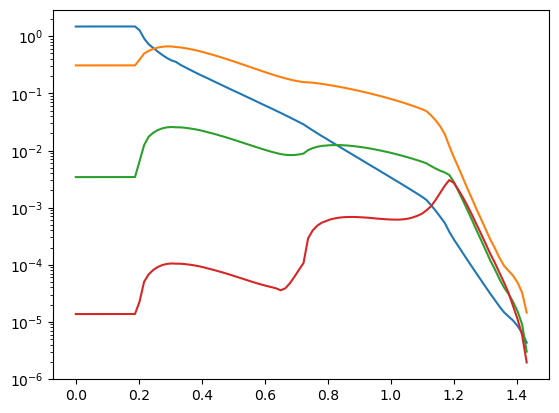

In [38]:
x = jnp.linspace(0,1.432,100)
y = jnp.full_like(x, 2.5)

xy = jnp.stack([x,y], axis=-1)

sols = [solution_domain.interpolate(xy, result.value[i,0]) for i in range(MGOP.n_energy_groups)]

plt.semilogy(x, onp.array(sols).T, label='g=0')

In [53]:
_ = MGOP.mv(jnp.ones((MGOP.n_energy_groups,) + MGOP.moment_operator.out_structure().shape))

In [59]:
%timeit _compute_xi_g_map(MGOP.n_energy_groups,MGOP.moment_operator.transpose(), MGOP.transport_operator.transpose(), MGOP.mass_operator.transpose(), jnp.ones((MGOP.n_energy_groups,) + MGOP.moment_operator.out_structure().shape), batch_size=None).block_until_ready()


97.9 ms ± 398 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
